In [29]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error,mean_absolute_percentage_error
from sklearn.tree import DecisionTreeRegressor
economy = "economy.xlsx"
df_e = pd.read_excel(economy)


busines = "business.xlsx"
df_b = pd.read_excel(busines)

## EL objetivo del negocio es desarrollar un modelo de machine learning que prediga el precio de un boleto de avion en funcion de diferentes caracteristicas de vuelo ##

Comprender el problema

Queremos ayudar a una agencia de viajes a estimar precios de boletos con precisión.

Factores que influyen en el precio: aerolínea, destino, temporada, clase de servicio, anticipación de compra, etc.

Beneficio: ofrecer precios competitivos y mejorar la experiencia del cliente.

Metodología

Carga de datos desde business.csv y economy.csv.

Limpieza y preprocesamiento: manejo de valores nulos, outliers y transformación de datos.

Análisis exploratorio: distribución de variables, correlaciones y visualización de datos.

Selección de variables: identificar las características más importantes para la predicción.

Modelado: probar al menos tres modelos de Machine Learning.

Optimización: ajustar hiperparámetros para mejorar el rendimiento.

Evaluación: comparar métricas y seleccionar el mejor modelo.

Variable objetivo

La variable a predecir es el precio del boleto (price).

Tareas clave

Análisis exploratorio de los datos.

Limpieza y transformación.

Creación de un pipeline de preprocesamiento.

Entrenamiento de modelos y optimización.

Evaluación y selección del mejor modelo.

Conclusiones y próximos pasos.

#### Empecemos  ####

#### primero importamos nuestros dos archivos de datos y los concatenamos en un solo dataframe, ya que tienen las mismas columnas ####

In [30]:
df_b['class'] = 'Business'
df_e['class'] = 'Economy'

In [31]:
df = pd.concat([df_b, df_e], axis=0, ignore_index=True)

In [32]:
df

,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price,class
0,2022-02-11,Air India,AI,868,18:00:00,Delhi,02h 00m,non-stop,20:00:00,Mumbai,25612,Business
1,2022-02-11,Air India,AI,624,19:00:00,Delhi,02h 15m,non-stop,21:15:00,Mumbai,25612,Business
2,2022-02-11,Air India,AI,531,20:00:00,Delhi,24h 45m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:45:00,Mumbai,42220,Business
3,2022-02-11,Air India,AI,839,21:25:00,Delhi,26h 30m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55:00,Mumbai,44450,Business
4,2022-02-11,Air India,AI,544,17:15:00,Delhi,06h 40m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55:00,Mumbai,46690,Business
...,...,...,...,...,...,...,...,...,...,...,...,...
300256,2022-03-31,Vistara,UK,832,07:05:00,Chennai,13h 50m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:55:00,Hyderabad,7697,Economy
300257,2022-03-31,Vistara,UK,832,07:05:00,Chennai,13h 50m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:55:00,Hyderabad,7709,Economy
300258,2022-03-31,Vistara,UK,826,12:30:00,Chennai,20h 35m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,09:05:00,Hyderabad,8640,Economy
300259,2022-03-31,Vistara,UK,822,09:45:00,Chennai,23h 20m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,09:05:00,Hyderabad,8640,Economy


#### Aqui revisamos la cantidad de nulos, valores unicos y tipos de datos de cada columna ####

In [33]:
def data_quality_analysis(df):
 
    result_df = pd.DataFrame(columns=['Columna', 'Tipo de dato', 'Valores únicos', 'Valores faltantes'])

    columns = df.columns
    data_types = df.dtypes.to_list()
    unique_values = [df[column].nunique() for column in columns]
    missing_values = [df[column].isnull().sum() for column in columns]

   
    result_df['Columna'] = columns
    result_df['Tipo de dato'] = data_types
    result_df['Valores únicos'] = unique_values
    result_df['Valores faltantes'] = missing_values

    return result_df




In [34]:
analysis_result = data_quality_analysis(df).set_index('Columna')
print(analysis_result.sort_values('Tipo de dato'))

              Tipo de dato  Valores únicos  Valores faltantes
Columna                                                      
date        datetime64[ns]              49                  0
num_code             int64            1255                  0
airline             object               8                  0
ch_code             object               8                  0
dep_time            object             251                  0
from                object               6                  0
time_taken          object             483                  0
stop                object              40                  0
arr_time            object             266                  0
to                  object               6                  0
price               object           12165                  0
class               object               2                  0


In [35]:
for col in ['airline', 'ch_code', 'dep_time', 'from', 'stop', 'to', 'class']:
    print(f"{col} valores vacíos o 'NaN':", df[col].isin(['', 'NaN', 'N/A']).sum())

airline valores vacíos o 'NaN': 0
ch_code valores vacíos o 'NaN': 0
dep_time valores vacíos o 'NaN': 0
from valores vacíos o 'NaN': 0
stop valores vacíos o 'NaN': 0
to valores vacíos o 'NaN': 0
class valores vacíos o 'NaN': 0


In [36]:
df["price"] = df["price"].replace(r"[^\d.]", "", regex=True).astype(float)
# para eliminar los caracteres no numéricos y convertir a float

In [37]:
df['time_taken'] = df['time_taken'].str.extract(r'(?:(\d+)h)?\s*(?:(\d+)m)?').fillna(0).astype(int).apply(lambda x: x[0]*60 + x[1], axis=1)
# Pasamos el tiempo a minutos

In [38]:
df['dep_time'] = pd.to_datetime(df['dep_time'], format='%H:%M:%S').dt.time
df['arr_time'] = pd.to_datetime(df['arr_time'], format='%H:%M:%S').dt.time
# Aqui convertimos las horas a formato de 24 horas

In [39]:
df['stop'] = df['stop'].str.split('\n').str[0].str.strip()
# aqui eliminamos los espacios en blanco y el salto de linea

In [40]:
print(df['to'].value_counts())

to
Mumbai       59109
Delhi        57361
Bangalore    51112
Kolkata      49535
Hyderabad    42776
Chennai      40368
Name: count, dtype: int64


In [41]:
print(df['ch_code'].value_counts())

ch_code
UK    127859
AI     80894
6E     43120
G8     23177
I5     16098
SG      9011
S5        61
2T        41
Name: count, dtype: int64


In [42]:
print(df['from'].value_counts())

from
Delhi        61345
Mumbai       60903
Bangalore    52106
Kolkata      46347
Hyderabad    40860
Chennai      38700
Name: count, dtype: int64


#### Ahora vamos aver la distribucion de alguna variables ####

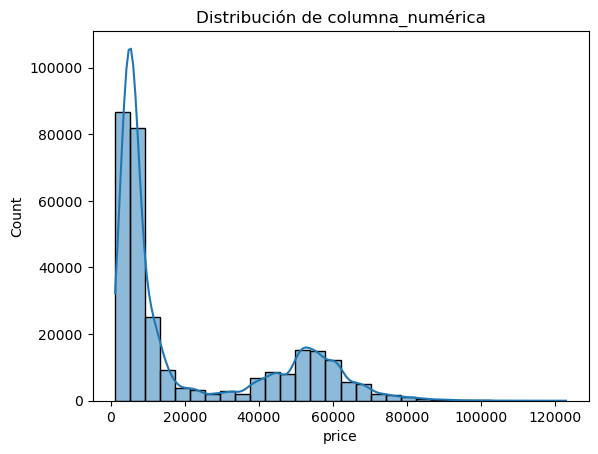

In [43]:
sns.histplot(df["price"], bins=30, kde=True)
plt.title("Distribución de columna_numérica")
plt.show()


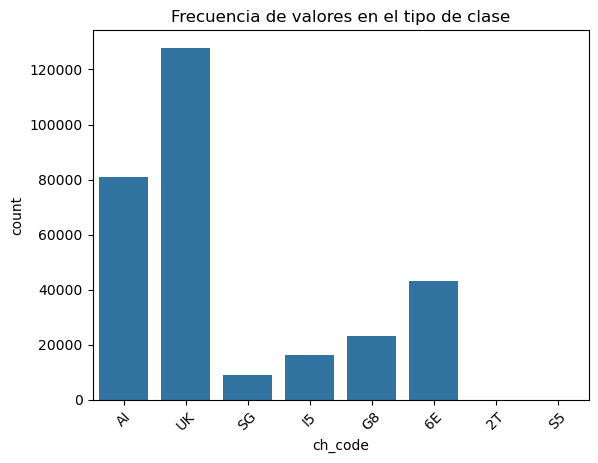

In [44]:
sns.countplot(x=df["ch_code"])
plt.xticks(rotation=45)
plt.title("Frecuencia de valores en el tipo de clase")
plt.show()

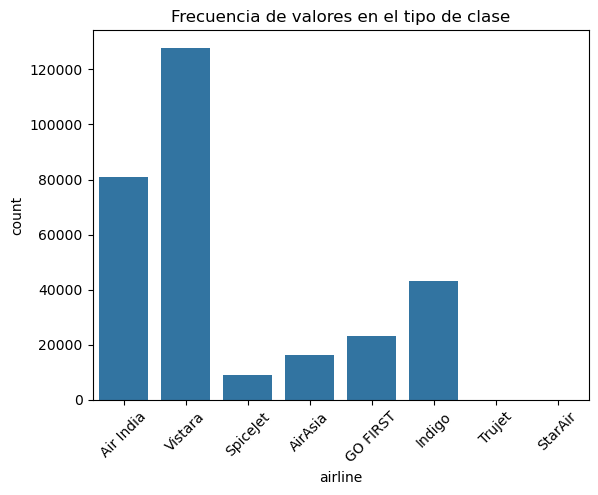

In [45]:
sns.countplot(x=df["airline"])
plt.xticks(rotation=45)
plt.title("Frecuencia de valores en el tipo de clase")
plt.show()

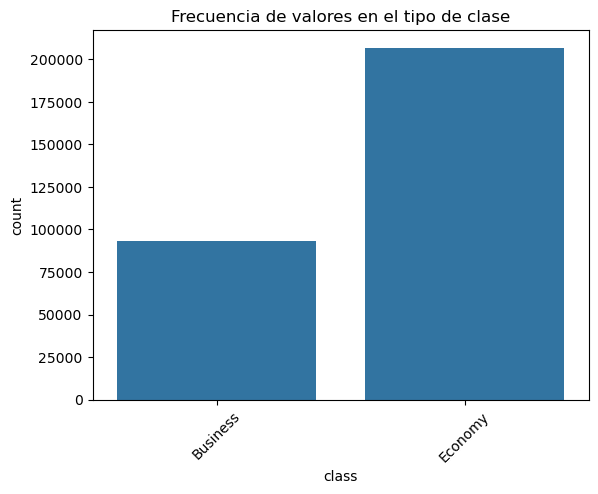

In [46]:
sns.countplot(x=df["class"])
plt.xticks(rotation=45)
plt.title("Frecuencia de valores en el tipo de clase")
plt.show()

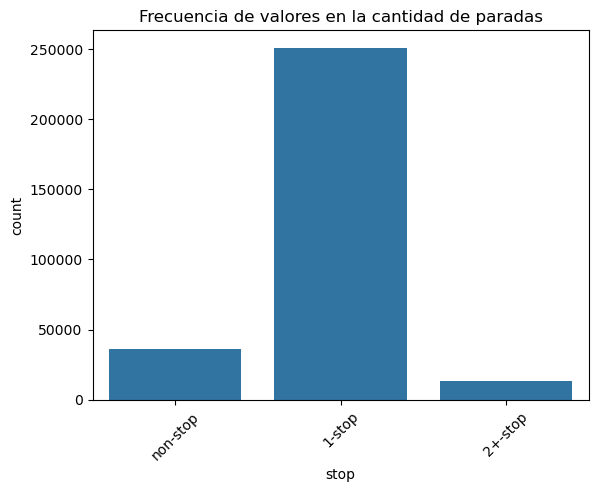

In [47]:
sns.countplot(x=df["stop"])
plt.xticks(rotation=45)
plt.title("Frecuencia de valores en la cantidad de paradas")
plt.show()

#### Calculamos los outliers ####

In [48]:
def plot_boxplot_with_outliers(data, column_name, outlier_color='red', factor=1.5):
    # Calcular los estadísticos clave
    Q1 = data[column_name].quantile(0.25)
    Q3 = data[column_name].quantile(0.75)
    IQR = Q3 - Q1

    # Calcular los límites para los valores atípicos
    lower_bound = Q1 - factor * IQR
    upper_bound = Q3 + factor * IQR


    # Crear un gráfico de diagrama de caja (boxplot)
    plt.figure(figsize=(8,10))
    sns.boxplot(y=data[column_name], showfliers=False)
    # plt.title(f'Diagrama de Caja de {column_name}')
    plt.ylabel(column_name)
    plt.xlabel('Datos')

    # Resaltar los valores atípicos en un color diferente
    outliers = data[(data[column_name] < lower_bound) | (data[column_name] > upper_bound)]
    plt.scatter(y=outliers[column_name], x=[0]*len(outliers), color=outlier_color, label='Outliers')

    # Anotar los valores de límites y cuartiles en el gráfico
    plt.text(0.35, Q1-0.55, f'Q1: {Q1:.2f}', fontsize=10)
    plt.text(0.35, Q3+0.3, f'Q3: {Q3:.2f}', fontsize=10)
    plt.text(0.205, lower_bound, f'Límite Inferior: {lower_bound:.2f}', fontsize=10)
    plt.text(0.205, upper_bound, f'Límite Superior: {upper_bound:.2f}', fontsize=10)

    plt.legend()
    plt.show()
    return outliers


Analizando outliers en: time_taken


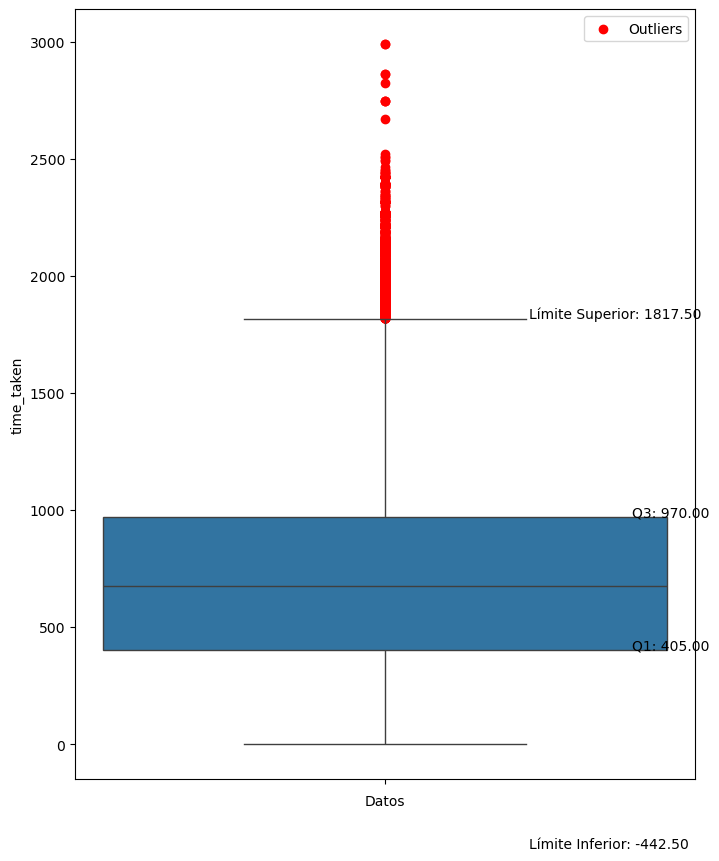

Número de outliers en time_taken: 2004

Analizando outliers en: price


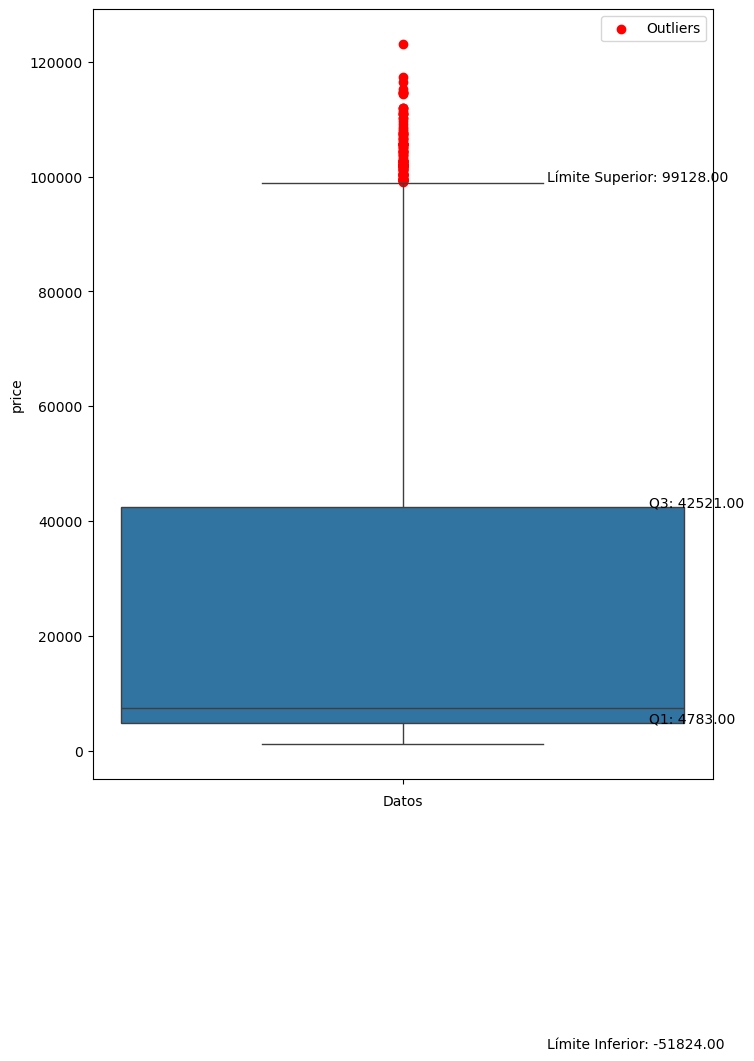

Número de outliers en price: 123


In [49]:
columns_to_analyze = ['time_taken', 'price']
outliers_dict = {}  
for column in columns_to_analyze:
    print(f"\nAnalizando outliers en: {column}")
    outliers = plot_boxplot_with_outliers(df, column, outlier_color='red', factor=1.5)
    outliers_dict[column] = outliers
    print(f"Número de outliers en {column}: {len(outliers)}")

#### Decidi no eliminar los outliers. Ya que en tiempo de vuelo y en precio son valores completamente reales y tienen sentido ####

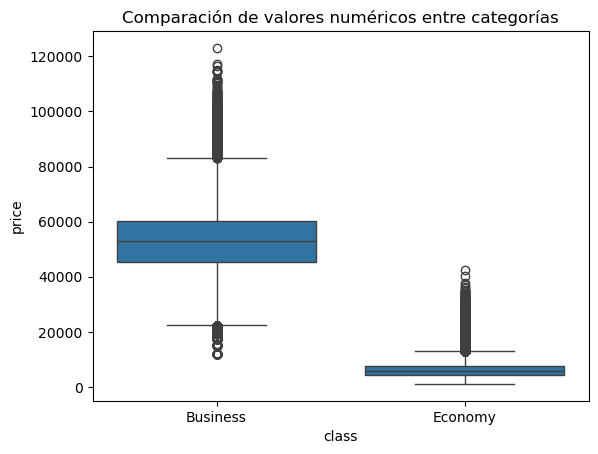

In [50]:
sns.boxplot(x=df["class"], y=df["price"])
plt.title("Comparación de valores numéricos entre categorías")
plt.show()

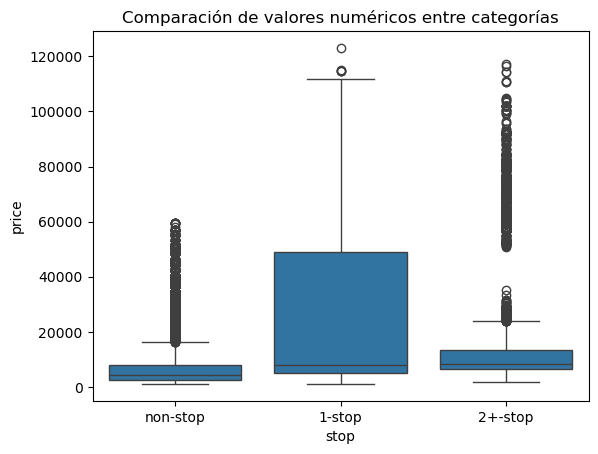

In [51]:
sns.boxplot(x=df["stop"], y=df["price"])
plt.title("Comparación de valores numéricos entre categorías")
plt.show()

#### Aplicamos label encoder y one hot encoder ####

In [52]:
le = LabelEncoder()
colums_to_enconde = ['stop', 'class']
for col in colums_to_enconde:
    df[col] = le.fit_transform(df[col])

In [53]:
df = pd.get_dummies(df, columns=['from', 'to', 'airline','ch_code'], drop_first=True)

#### Y vemos las relaciones entre las variables numericas ####

<Axes: >

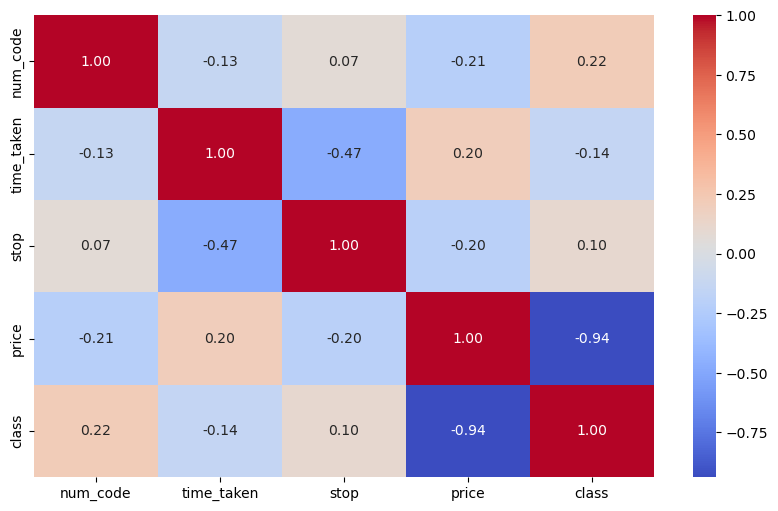

In [54]:
plt.figure(figsize=(10, 6))
numeric_df = df.select_dtypes(include=['number'])  
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")

In [62]:

X = df.drop("price", axis=1).select_dtypes(include=['number'])
y = df["price"]

f_values, p_values = f_regression(X, y)

anova = pd.DataFrame({
    "Variable": X.columns,
    "F-Value": f_values,
    "P-Value": p_values
}).sort_values(by="F-Value", ascending=False)
print("\n📈 ANOVA (Ranking de Variables):")
print(anova)
# Aquí se muestran las variables con mayor valor F y menor p-valor, indicando su relevancia en la predicción de la variable dependiente.


📈 ANOVA (Ranking de Variables):
     Variable       F-Value  P-Value
3       class  2.193516e+06      0.0
0    num_code  1.425088e+04      0.0
1  time_taken  1.310130e+04      0.0
2        stop  1.286846e+04      0.0


### Separamos los datos en entrenamiento y test ### 

In [63]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

#### Estandarizamos ####

In [64]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [65]:
# Aqui creamos un diccionario con los modelos y sus hiperparámetros para la búsqueda de cuadrícula (GridSearchCV)
models = {
    "LinearRegression": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"alpha": [0.1, 1.0, 10.0]}),
    "Lasso": (Lasso(), {"alpha": [0.001, 0.01, 0.1, 1.0]}),
    "ElasticNet": (ElasticNet(), {"alpha": [0.01, 0.1, 1.0], "l1_ratio": [0.2, 0.5, 0.8]}),
    "Árbol de Decisión": (DecisionTreeRegressor(random_state=42), {"max_depth": [1,3, 5, 10, None], 
                                                                   "min_samples_split": [2, 5, 10,20]}),
    "RandomForest": (RandomForestRegressor(random_state=42), {"n_estimators": [100, 200,500], "max_depth": [None, 10, 20]})
}

In [66]:
# Aqui inicializamos una lista para almacenar los resultados
results = []
# Iteramos sobre los modelos y sus hiperparámetros 
for name, (model, params) in models.items():
    print(f"🔍 Entrenando modelo: {name}")
    grid = GridSearchCV(model, params, cv=5, scoring="r2", n_jobs=-1)
    grid.fit(X_train_scaled, y_train)
    y_pred = grid.predict(X_test_scaled)
    results.append({
        "Model": name,
        "Best Params": grid.best_params_,
        "R2 Score": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAPE": mean_absolute_percentage_error(y_test, y_pred)
    })

🔍 Entrenando modelo: LinearRegression
🔍 Entrenando modelo: Ridge
🔍 Entrenando modelo: Lasso
🔍 Entrenando modelo: ElasticNet
🔍 Entrenando modelo: Árbol de Decisión
🔍 Entrenando modelo: RandomForest


In [67]:
results_df = pd.DataFrame(results)
print("\n📋 Comparación de modelos:")
results_df


📋 Comparación de modelos:


,Model,Best Params,R2 Score,MAE,RMSE,MAPE
0,LinearRegression,{},0.891302,5085.528677,7479.675050,0.494168
1,Ridge,{'alpha': 1.0},0.891302,5085.538368,7479.675084,0.494170
2,Lasso,{'alpha': 0.001},0.891302,5085.528501,7479.675050,0.494168
3,ElasticNet,"{'alpha': 0.01, 'l1_ratio': 0.8}",0.891298,5089.666975,7479.812736,0.495296
4,Árbol de Decisión,"{'max_depth': None, 'min_samples_split': 5}",0.974058,2229.310048,3654.056168,0.237561
5,RandomForest,"{'max_depth': None, 'n_estimators': 500}",0.974492,2230.117813,3623.347914,0.238504


Análisis de los modelos
Regresión Lineal, Ridge, Lasso y ElasticNet

Todas las regresiones tienen R² ≈ 0.89, lo que indica un ajuste decente, pero no el mejor.

MAE y RMSE están cerca de 5000 y 7500, lo que indica un error relativamente alto en la predicción del precio.

La diferencia entre los modelos de regresión es mínima, lo que sugiere que los datos no se benefician mucho de la regularización (alpha).

Árbol de Decisión

R² = 0.974, lo que significa que explica el 97.4% de la varianza.

MAE = 2229 y RMSE = 3654, mucho mejor que la regresión.

El hecho de que max_depth=None haya sido elegido sugiere que el árbol está bastante profundo.

Random Forest

R² = 0.9744, ligeramente mejor que el árbol de decisión.

MAE y RMSE son similares al árbol de decisión, pero un poco mejores.

Esto indica que RandomForest ayuda a mejorar la generalización respecto a un solo árbol.

In [68]:
baseline_pred = np.mean(y_test)
baseline_mae = np.mean(np.abs(y_test - baseline_pred))
baseline_rmse = np.sqrt(np.mean((y_test - baseline_pred)**2))
baseline_r2 = 1 - (np.sum((y_test - baseline_pred)**2) / np.sum((y_test - np.mean(y_test))**2))

C:\Users\gabby\AppData\Local\Temp\ipykernel_18004\4025653585.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Modelo', y='R2', data=results_df, palette="viridis")


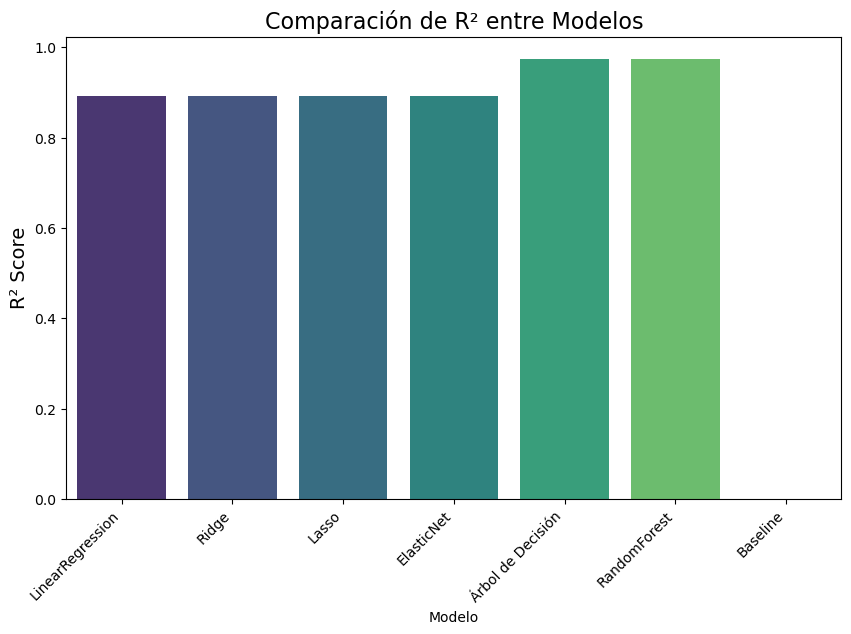

C:\Users\gabby\AppData\Local\Temp\ipykernel_18004\4025653585.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Modelo', y='MAE', data=results_df, palette="viridis")


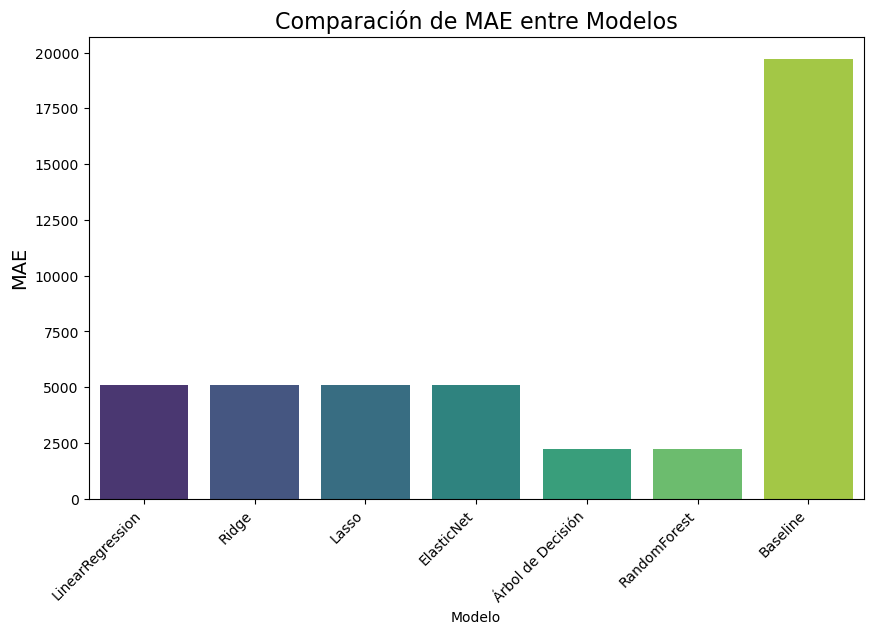

C:\Users\gabby\AppData\Local\Temp\ipykernel_18004\4025653585.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Modelo', y='RMSE', data=results_df, palette="viridis")


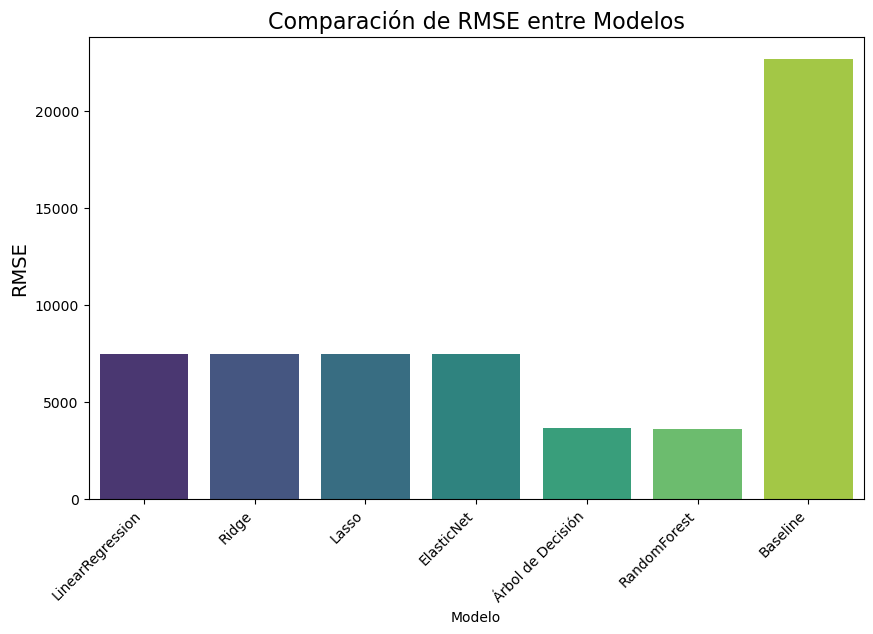

In [69]:
results_dict = {
    'Modelo': ['LinearRegression', 'Ridge', 'Lasso', 'ElasticNet', 'Árbol de Decisión', 'RandomForest', 'Baseline'],
    'R2': [0.891302, 0.891302, 0.891302, 0.891298, 0.974058, 0.974492, baseline_r2],
    'MAE': [5085.528677, 5085.538368, 5085.528501, 5089.666975, 2229.310048, 2230.117813, baseline_mae],
    'RMSE': [7479.675050, 7479.675084, 7479.675050, 7479.812736, 3654.056168, 3623.347914, baseline_rmse],
}


import pandas as pd
results_df = pd.DataFrame(results_dict)


plt.figure(figsize=(10, 6))
sns.barplot(x='Modelo', y='R2', data=results_df, palette="viridis")
plt.title("Comparación de R² entre Modelos", fontsize=16)
plt.ylabel("R² Score", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.show()


plt.figure(figsize=(10, 6))
sns.barplot(x='Modelo', y='MAE', data=results_df, palette="viridis")
plt.title("Comparación de MAE entre Modelos", fontsize=16)
plt.ylabel("MAE", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.show()


plt.figure(figsize=(10, 6))
sns.barplot(x='Modelo', y='RMSE', data=results_df, palette="viridis")
plt.title("Comparación de RMSE entre Modelos", fontsize=16)
plt.ylabel("RMSE", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.show()

#### Ya que el que me parecio mejor fue el RandomForest, decidi hacer un grafico para visualizar las predicciones vs los valores reales ####

Text(0, 0.5, 'Predicciones')

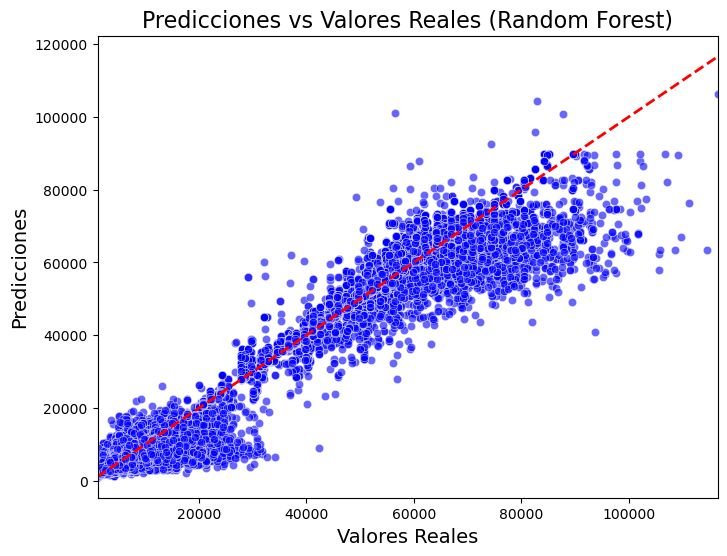

In [70]:
# Recreate the grid for Random Forest
rf_model = RandomForestRegressor(random_state=42)
rf_params = {"n_estimators": [100, 200, 500], "max_depth": [None, 10, 20]}
grid = GridSearchCV(rf_model, rf_params, cv=5, scoring="r2", n_jobs=-1)

# Fit the grid search on the training data
grid.fit(X_train_scaled, y_train)

# Predict using the best estimator
y_pred_rf = grid.best_estimator_.predict(X_test_scaled)

# Plot the predictions vs actual values
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred_rf, color='blue', alpha=0.6)

# Add a reference line
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)

plt.xlim(y_test.min(), y_test.max())
plt.title("Predicciones vs Valores Reales (Random Forest)", fontsize=16)
plt.xlabel("Valores Reales", fontsize=14)
plt.ylabel("Predicciones", fontsize=14)

Tras entrenar y evaluar múltiples modelos de regresión (como Regresión Lineal, Ridge, Lasso, ElasticNet, Árbol de Decisión y Random Forest) y compararlos con un baseline que predice la media de los valores, los resultados muestran que los modelos más complejos como Árbol de Decisión y Random Forest han superado al baseline y otros modelos más simples, obteniendo un R² mucho más alto, lo que indica una mejor capacidad para capturar la relación entre las variables de entrada y la variable objetivo (price).

Puntos Clave:
Random Forest y Árbol de Decisión tienen un rendimiento significativamente superior en comparación con modelos más simples, con un R² cercano a 0.97, lo que implica que estos modelos son capaces de explicar más del 97% de la variabilidad de los precios.

Los modelos lineales como LinearRegression, Ridge y Lasso también ofrecen buenos resultados, con un R² de aproximadamente 0.89, aunque no son tan efectivos como los modelos basados en árboles para este tipo de datos.

El baseline (predicción de la media) muestra una capacidad muy limitada para predecir correctamente el precio de los vuelos, como era de esperar.

Este análisis es útil para resolver el problema propuesto de predecir el precio de un vuelo, ya que permite identificar los modelos más adecuados. En este caso, los modelos basados en Árboles de Decisión y Random Forest son los más prometedores, ya que tienen la capacidad de capturar relaciones no lineales entre las características de los vuelos (como la cantidad de paradas, la clase, etc.) y el precio.

In [72]:
import joblib

# Suponiendo que `grid.best_estimator_` es tu modelo entrenado con los mejores parámetros
joblib.dump(grid.best_estimator_, "modelo_precio_vuelos.pkl")

['modelo_precio_vuelos.pkl']

In [76]:
# Cargar el modelo guardado
modelo = joblib.load("modelo_precio_vuelos.pkl")

# Suponé que tenés un nuevo ejemplo de vuelo en formato DataFrame
nuevo_vuelo = pd.DataFrame({
    'airline': ['IndiGo'],
    'ch_code': ['6E'],
    'num_code': [123],
    'dep_time': ['06:00'],
    'from': ['Delhi'],
    'time_taken': ['2h 50m'],
    'stop': ['non-stop'],
    'arr_time': ['08:50'],
    'to': ['Mumbai'],
    'class': ['Economy']
})

# Aplicar el mismo procesamiento que hiciste con el dataset original
nuevo_vuelo['time_taken'] = nuevo_vuelo['time_taken'].str.extract(r'(?:(\d+)h)?\s*(?:(\d+)m)?').fillna(0).astype(int).apply(lambda x: x[0]*60 + x[1], axis=1)
nuevo_vuelo['stop'] = nuevo_vuelo['stop'].str.split('\n').str[0].str.strip()
nuevo_vuelo['dep_time'] = pd.to_datetime(nuevo_vuelo['dep_time'], format='%H:%M').dt.time
nuevo_vuelo['arr_time'] = pd.to_datetime(nuevo_vuelo['arr_time'], format='%H:%M').dt.time

# Label encoding
for col in ['stop', 'class']:
    nuevo_vuelo[col] = nuevo_vuelo[col].apply(lambda x: le.transform([x])[0] if x in le.classes_ else le.transform([le.classes_[0]])[0])

# One-hot encoding
nuevo_vuelo = pd.get_dummies(nuevo_vuelo, columns=['from', 'to', 'airline', 'ch_code'], drop_first=True)

# Asegurarse de que las columnas coincidan con las del modelo
missing_cols = set(X.columns) - set(nuevo_vuelo.columns)
for col in missing_cols:
    nuevo_vuelo[col] = 0
nuevo_vuelo = nuevo_vuelo[X.columns]

# Escalar los datos
nuevo_vuelo_scaled = scaler.transform(nuevo_vuelo)

# Después, predecís el precio
precio_estimado = modelo.predict(nuevo_vuelo_scaled)
print(f"💸 Precio estimado del vuelo: ${precio_estimado[0]:,.2f}")

💸 Precio estimado del vuelo: $5,251.39
